# Практика 19. Класифікація математичних моделей

**Студент:** Huz_Yurii  
**Група:** IT-41  
**Варіант:** N=3, Одеса

Мета: класифікувати модель прогнозу споживання електроенергії, підібрати лінійну залежність за даними свого варіанта, оцінити адекватність за R² і залишками та конкретно розмежувати верифікацію й валідацію.

## Завдання 1. Класифікація сценарію

- **Стохастична.** Середня залежність `a + b × температура` детермінована, але споживання містить випадкове відхилення з рівнем шуму σ=60 МВт·год. Отже, повний сценарій — детермінована середня частина плюс випадкова складова, а не суто детермінована формула.
- **Описова/прогнозна, не балансова, не оптимізаційна і не імітаційна.** Рівняння оцінює споживання за температурою. Воно не виражає закон збереження ресурсу, не шукає найкраще рішення та не моделює послідовність станів системи крок за кроком у часі.
- **Статична.** Прогноз на місяць залежить лише від температури цього самого місяця. У формулі немає попереднього споживання, стану запасів або іншої часової залежності. Те, що спостереження впорядковані за місяцями, саме по собі не робить модель динамічною.

## Дані варіанта N=3

Одеса: середньорічна температура 11.5°C, амплітуда 13°C, базове споживання 3100 МВт·год, нахил генератора 35 МВт·год/°C і σ=60 МВт·год. Seed дорівнює номеру варіанта; дані синтетичні, але саме ці 12 спостережень вважаються вихідними для завдань.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(3)
city = "Одеса"
base_temp = 11.5
amplitude = 13
base_consumption = 3100
k = 35
noise_sd = 60

months = np.arange(1, 13)
temp = base_temp + amplitude * np.cos((months - 7) / 12 * 2 * np.pi)
temp = np.round(temp + np.random.normal(0, 0.5, size=12), 1)
consumption = base_consumption - k * (temp - base_temp) + np.random.normal(0, noise_sd, size=12)
consumption = np.round(consumption, 0)

city_data = pd.DataFrame({
    "місяць": months,
    "температура": temp,
    "споживання_МВтгод": consumption,
})
display(city_data)

,місяць,температура,споживання_МВтгод
0,1,-0.6,3576.0
1,2,0.5,3588.0
2,3,5.0,3331.0
3,4,10.6,3107.0
4,5,17.9,2843.0
5,6,22.6,2619.0
6,7,24.5,2704.0
7,8,22.4,2652.0
8,9,18.0,2801.0
9,10,11.3,3095.0


## Завдання 2. Підбір простої лінійної моделі

Оцінимо коефіцієнти методом найменших квадратів. За механікою сценарію нахил очікується від'ємним: зростання температури має зменшувати потребу в опаленні й загальне споживання.

In [2]:
b, a = np.polyfit(city_data["температура"], city_data["споживання_МВтгод"], 1)
city_data["передбачення"] = a + b * city_data["температура"]
print(f"Модель: споживання ≈ {a:.1f} + ({b:.1f}) × температура")
print(f"Оцінений нахил b={b:.3f} МВт·год/°C; знак {'від’ємний і узгоджується' if b < 0 else 'додатний і не узгоджується'} з очікуваним спадом споживання при потеплінні.")

Модель: споживання ≈ 3553.8 + (-39.3) × температура
Оцінений нахил b=-39.334 МВт·год/°C; знак від’ємний і узгоджується з очікуваним спадом споживання при потеплінні.


## Завдання 3. Залишки, R² та адекватність

Залишок — це спостережене споживання мінус передбачене. Перевіримо і частку поясненого розкиду, і структуру відхилень за місяцями та температурою.

,місяць,температура,споживання_МВтгод,передбачення,залишок
0,1,-0.6,3576.0,3577.40,-1.40
1,2,0.5,3588.0,3534.14,53.86
2,3,5.0,3331.0,3357.13,-26.13
3,4,10.6,3107.0,3136.86,-29.86
4,5,17.9,2843.0,2849.72,-6.72
5,6,22.6,2619.0,2664.85,-45.85
6,7,24.5,2704.0,2590.12,113.88
7,8,22.4,2652.0,2672.72,-20.72
8,9,18.0,2801.0,2845.79,-44.79
9,10,11.3,3095.0,3109.33,-14.33


SS залишків = 26583.26; SS загальна = 1532230.92; R² = 0.982651 (98.27%).


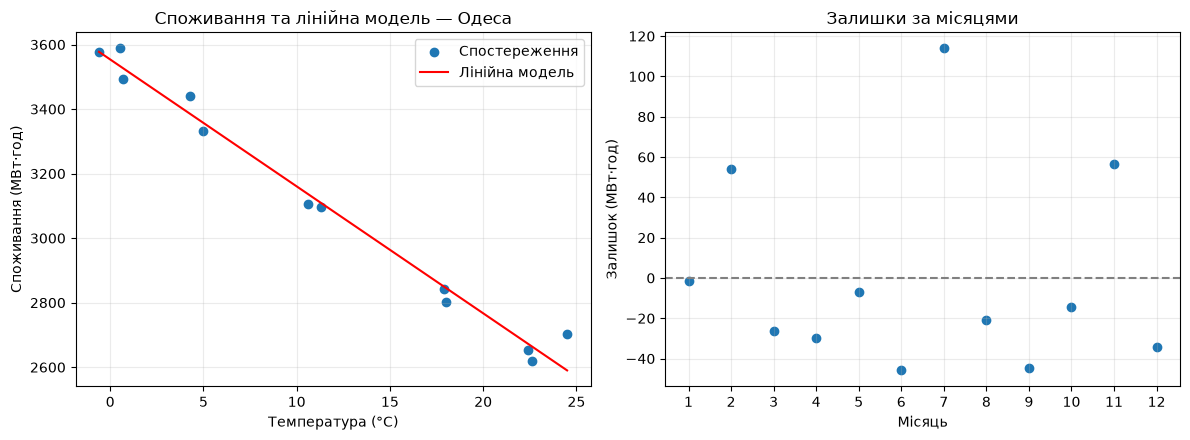

Залишки за місяцями: [-1.4, 53.9, -26.1, -29.9, -6.7, -45.9, 113.9, -20.7, -44.8, -14.3, 56.3, -34.3]


In [3]:
city_data["залишок"] = city_data["споживання_МВтгод"] - city_data["передбачення"]
ss_res = (city_data["залишок"] ** 2).sum()
ss_tot = ((city_data["споживання_МВтгод"] - city_data["споживання_МВтгод"].mean()) ** 2).sum()
r_squared = 1 - ss_res / ss_tot

display(city_data[["місяць", "температура", "споживання_МВтгод", "передбачення", "залишок"]].round(2))
print(f"SS залишків = {ss_res:.2f}; SS загальна = {ss_tot:.2f}; R² = {r_squared:.6f} ({100*r_squared:.2f}%).")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.scatter(city_data["температура"], city_data["споживання_МВтгод"], label="Спостереження")
temperature_line = np.linspace(city_data["температура"].min(), city_data["температура"].max(), 200)
ax1.plot(temperature_line, a + b * temperature_line, color="red", label="Лінійна модель")
ax1.set_xlabel("Температура (°C)")
ax1.set_ylabel("Споживання (МВт·год)")
ax1.set_title("Споживання та лінійна модель — Одеса")
ax1.legend()
ax1.grid(alpha=0.25)

ax2.scatter(city_data["місяць"], city_data["залишок"])
ax2.axhline(0, color="gray", linestyle="--")
ax2.set_xticks(months)
ax2.set_xlabel("Місяць")
ax2.set_ylabel("Залишок (МВт·год)")
ax2.set_title("Залишки за місяцями")
ax2.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Залишки за місяцями:", [round(float(value), 1) for value in city_data["залишок"]])

**Оцінка для цього набору.** R² ≈ **0.983**: лінійна залежність пояснює близько 98.3% вибіркового розкиду споживання навколо середнього, а близько 1.7% нею не пояснено. Залишки коливаються по обидва боки нуля й не демонструють послідовного зростання/спадання від зими до літа; помітний окремий додатний залишок у липні, приблизно **+113.9 МВт·год**, та додатні відхилення в лютому й листопаді. Інші місяці здебільшого мають помірні відхилення. За цих 12 синтетичних спостережень виразного систематичного сезонного недо-/переоцінювання не видно, але липнева точка заслуговує уваги. У сукупності високе R² і відсутність послідовного патерну залишків підтримують адекватність простої прямої для опису цього набору, але не доводять її універсальної правильності чи придатності для екстраполяції.

## Завдання 4. Верифікація та валідація

**Верифікація коду підбору.** Перевіримо для січня, що передбачення з масиву відповідає прямій формулі `a + b × температура`; ця перевірка контролює правильність реалізації обчислення, а не відповідність реальним вимірам.

In [4]:
january = city_data.iloc[0]
manual_january_prediction = a + b * january["температура"]
code_january_prediction = january["передбачення"]
print(f"Січень: температура={january['температура']:.1f}°C")
print(f"Ручний розрахунок a + b×T = {a:.6f} + ({b:.6f})×({january['температура']:.1f}) = {manual_january_prediction:.3f} МВт·год")
print(f"Передбачення коду = {code_january_prediction:.3f} МВт·год")
assert np.isclose(manual_january_prediction, code_january_prediction)
print("Верифікацію цієї арифметичної операції пройдено: ручний і програмний результати збігаються.")

Січень: температура=-0.6°C
Ручний розрахунок a + b×T = 3553.802016 + (-39.333996)×(-0.6) = 3577.402 МВт·год
Передбачення коду = 3577.402 МВт·год
Верифікацію цієї арифметичної операції пройдено: ручний і програмний результати збігаються.


**Валідація моделі.** Порівняння передбачень із цими самими 12 місяцями показує, наскільки пряма описує навчальні спостереження, але це не незалежна перевірка прогнозної здатності: коефіцієнти `a` і `b` підібрано саме на них. Для чеснішої валідації потрібні не використані під час підбору дані — наприклад, місячні температури й споживання Одеси за наступний рік. Тоді фіксуємо вже підібрані коефіцієнти, прогнозуємо новий рік і аналізуємо його помилки. Отже, код можна верифікувати на цьому ноутбуці, але реальну прогностичну валідність на нових роках ці 12 спостережень самі по собі не встановлюють.

## Завдання 5. Чи потрібно ускладнювати модель?

Для цього навчального набору R² високе, а залишки не мають чіткого послідовного сезонного патерну, тому як першу компактну модель прогнозу за температурою доцільно залишити пряму `a + b × температура`, а не додавати параметри лише заради ще кращого R² на тих самих 12 точках. Це відповідає компромісу точність–простота: простіша модель легше тлумачиться й має менший ризик підлаштування до шуму. Водночас липневий залишок близько +113.9 МВт·год варто перевірити на незалежних роках; якщо повторюється систематичне недооцінювання влітку, тоді можна тестувати сезонний/квадратичний доданок або додаткову змінну й оцінювати зміну похибки на відкладених даних. Високий R² на одному синтетичному році сам по собі не є підставою відкидати таку перевірку.

## Контрольні питання

1. **Верифікація й валідація для цієї моделі.** Верифікація перевіряє реалізацію: для січневої температури −0.6°C ручний розрахунок `a + b×T` має дорівнювати значенню, записаному кодом (обчислення це перевіряє через `np.isclose`). Валідація перевіряє відповідність моделі незалежним спостереженням; потрібен, наприклад, наступний рік, не використаний для оцінювання коефіцієнтів.
2. **Незалежні осі класифікації.** Стохастичність описує наявність випадкової складової; статичність — чи залежить стан від попередніх моментів часу; тип за метою — чи є рівняння балансу, пошук оптимуму або симуляція. Тому висновки «стохастична», «статична» та «описова/прогнозна» не суперечать одне одному, а відповідають на різні питання.
3. **Зміст R² та екстраполяція.** Отримане R² показує частку варіації цих 12 спостережень, описану прямою відносно їхнього середнього. Воно не доводить, що модель є «правильною» для майбутніх років, не замінює аналізу залишків і не гарантує надійності поза діапазоном температур, на яких її підібрано.
4. **Чому важлива структура залишків?** Сумарна міра на кшталт R² стискає всі похибки до одного числа й приховує, де саме вони виникають. Послідовний тренд або сезонні групи одного знака вказували б на пропущену структуру; випадкові коливання навколо нуля узгоджуються з шумом. Тому графік залишків виявляє систематичну помилку, яку саме число R² може приховати.

## Підсумок

Для Одеси (N=3) класифіковано стохастичну статичну описову модель, побудовано лінійну залежність споживання від температури, проаналізовано залишки й R², перевірено конкретне обчислення передбачення та пояснено, чому для валідації потрібні незалежні дані.